# Credit Default Prediction: Performance, Calibration and Group-Level Error Analysis

## Project Overview

This project investigates how different machine-learning models compare when predicting credit-card payment default.

Using the UCI Default of Credit Card Clients dataset, the study evaluates four classification models: Logistic Regression, Decision Tree, Random Forest and Gradient Boosting.

Beyond predictive performance, the project examines probability calibration and group-level error rates to explore the trade-offs involved in selecting machine-learning models for high-stakes financial decisions.

## Research Question

How do different machine-learning models compare in predictive performance, probability calibration and group-level error rates when predicting credit-card payment default, and what trade-offs emerge when selecting a model for a high-stakes decision?

## Project Objectives

1. Explore and prepare the credit-card default dataset.
2. Train and compare four machine-learning classification models.
3. Evaluate predictive performance using multiple classification metrics.
4. Examine probability calibration.
5. Investigate differences in error rates across demographic groups.
6. Discuss model limitations and responsible AI considerations.

## Tools and Technologies

- Python
- Google Colab
- pandas and NumPy
- scikit-learn
- Matplotlib

In [1]:
print("hello, Beyond Accuracy")
print("My first AI/ML project")

hello, Beyond Accuracy
My first AI/ML project


In [2]:
pip install ucimlrepo

# 1. Data Loading and Initial Inspection

This section loads the credit-card default dataset and examines its structure, dimensions, column names and initial records. The aim is to understand the available data before beginning the analysis.

In [3]:
!pip install ucimlrepo

from ucimlrepo import fetch_ucirepo

# Load the dataset
dataset = fetch_ucirepo(id=350)

# Store the features and target
X = dataset.data.features
y = dataset.data.targets

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
print("Number of rows:", X.shape[0])
print("Number of features:", X.shape[1])
print("Target shape:", y.shape)

Number of rows: 30000
Number of features: 23
Target shape: (30000, 1)


In [5]:
X.head()

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23
0,20000,2,2,1,24,2,2,-1,-1,-2,...,689,0,0,0,0,689,0,0,0,0
1,120000,2,2,2,26,-1,2,0,0,0,...,2682,3272,3455,3261,0,1000,1000,1000,0,2000
2,90000,2,2,2,34,0,0,0,0,0,...,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000
3,50000,2,2,1,37,0,0,0,0,0,...,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000
4,50000,1,2,1,57,-1,0,-1,0,0,...,35835,20940,19146,19131,2000,36681,10000,9000,689,679


In [6]:
y.head()

,Y
0,1
1,1
2,0
3,0
4,0


In [7]:
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget column name:")
print(y.columns.tolist())

print("\nFirst five target values:")
print(y.head())

Feature shape: (30000, 23)
Target shape: (30000, 1)

Target column name:
['Y']

First five target values:
   Y
0  1
1  1
2  0
3  0
4  0


In [8]:
# Count each outcome
print("Target value counts:")
print(y["Y"].value_counts().sort_index())

# Calculate the percentage of each outcome
print("\nTarget percentages:")
print((y["Y"].value_counts(normalize=True).sort_index() * 100).round(2))

Target value counts:
Y
0    23364
1     6636
Name: count, dtype: int64

Target percentages:
Y
0    77.88
1    22.12
Name: proportion, dtype: float64


In [9]:
# Count missing values in each feature
missing_values = X.isnull().sum()

print("Total missing values:", missing_values.sum())

print("\nFeatures with missing values:")
print(missing_values[missing_values > 0])

Total missing values: 0

Features with missing values:
Series([], dtype: int64)


In [10]:
# Count rows that are exact duplicates
duplicate_count = X.duplicated().sum()

print("Number of duplicate feature rows:", duplicate_count)

Number of duplicate feature rows: 56


In [11]:
# Find rows with duplicate feature values
duplicate_mask = X.duplicated(keep=False)

# Combine features and target for investigation
data = X.copy()
data["Y"] = y["Y"].values

# Show duplicate feature rows alongside their outcomes
duplicate_rows = data[duplicate_mask].sort_values(
    by=list(X.columns)
)

print("Number of rows involved in duplicate groups:",
      duplicate_mask.sum())

print("\nTarget distribution among these rows:")
print(duplicate_rows["Y"].value_counts().sort_index())

print("\nFirst 10 duplicate rows:")
display(duplicate_rows.head(10))

Number of rows involved in duplicate groups: 108

Target distribution among these rows:
Y
0    76
1    32
Name: count, dtype: int64

First 10 duplicate rows:


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
12430,20000,1,2,2,24,2,2,4,4,4,...,1650,1650,1650,0,0,0,0,0,0,1
12432,20000,1,2,2,24,2,2,4,4,4,...,1650,1650,1650,0,0,0,0,0,0,0
14294,20000,1,2,2,24,2,2,4,4,4,...,1650,1650,1650,0,0,0,0,0,0,1
1759,50000,1,2,2,26,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
10250,50000,1,2,2,26,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
7170,50000,2,1,2,23,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
17032,50000,2,1,2,23,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
291,50000,2,2,2,22,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,1
8297,50000,2,2,2,22,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
1983,80000,1,1,2,37,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,1


In [12]:
# Count unique feature combinations associated with each outcome
outcome_counts = data.groupby(list(X.columns))["Y"].nunique()

# Count combinations that have more than one outcome
conflicting_groups = outcome_counts[outcome_counts > 1]

print("Duplicate feature groups with conflicting outcomes:",
      len(conflicting_groups))

Duplicate feature groups with conflicting outcomes: 21


In [13]:
print("Outcome counts within conflicting groups:")

outcome_counts_by_features = (
    data.groupby(list(X.columns))["Y"]
        .value_counts()
        .unstack(fill_value=0)
)

print(
    outcome_counts_by_features
        .loc[conflicting_groups.index]
        .head(10)
)

Outcome counts within conflicting groups:
Y                                                                                             0  \
X1     X2 X3 X4 X5 X6 X7 X8 X9 X10 X11 X12  X13  X14  X15  X16  X17  X18 X19 X20 X21 X22 X23      
20000  1  2  2  24  2  2  4  4  4   4  1650 1650 1650 1650 1650 1650 0   0   0   0   0   0    1   
50000  2  2  2  22  1 -2 -2 -2 -2  -2  0    0    0    0    0    0    0   0   0   0   0   0    1   
80000  1  1  2  37  1 -2 -2 -2 -2  -2  0    0    0    0    0    0    0   0   0   0   0   0    1   
          3  2  27  1 -2 -2 -2 -2  -2  0    0    0    0    0    0    0   0   0   0   0   0    1   
100000 2  3  1  53  1 -2 -2 -2 -2  -2  0    0    0    0    0    0    0   0   0   0   0   0    1   
120000 2  2  2  28  1 -2 -2 -2 -2  -2  0    0    0    0    0    0    0   0   0   0   0   0    1   
130000 2  2  2  27  1 -2 -2 -2 -2  -2  0    0    0    0    0    0    0   0   0   0   0   0    1   
150000 2  1  1  32  1 -2 -2 -2 -2  -2  0    0    0    0    0    0  

In [14]:
categorical_columns = list(X.columns[1:4]) + list(X.columns[5:11])

for column in categorical_columns:
    print(f"\n{column}")
    print(X[column].value_counts().sort_index())


X2
X2
1    11888
2    18112
Name: count, dtype: int64

X3
X3
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

X4
X4
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64

X6
X6
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64

X7
X7
-2     3782
-1     6050
 0    15730
 1       28
 2     3927
 3      326
 4       99
 5       25
 6       12
 7       20
 8        1
Name: count, dtype: int64

X8
X8
-2     4085
-1     5938
 0    15764
 1        4
 2     3819
 3      240
 4       76
 5       21
 6       23
 7       27
 8        3
Name: count, dtype: int64

X9
X9
-2     4348
-1     5687
 0    16455
 1        2
 2     3159
 3      180
 4       69
 5       35
 6        5
 7       58
 8        2
Name: count, dtype: int64

X10
X10
-2     4546
-1     5539
 0    16947
 2     2626
 3      178
 4       84
 5       17
 6   

In [15]:
repayment_columns = ["X6", "X7", "X8", "X9", "X10", "X11"]

for column in repayment_columns:
    print(f"\n{column}")
    print(X[column].value_counts().sort_index().loc[[-2, -1, 0]])


X6
X6
-2     2759
-1     5686
 0    14737
Name: count, dtype: int64

X7
X7
-2     3782
-1     6050
 0    15730
Name: count, dtype: int64

X8
X8
-2     4085
-1     5938
 0    15764
Name: count, dtype: int64

X9
X9
-2     4348
-1     5687
 0    16455
Name: count, dtype: int64

X10
X10
-2     4546
-1     5539
 0    16947
Name: count, dtype: int64

X11
X11
-2     4895
-1     5740
 0    16286
Name: count, dtype: int64


# 2. Data Preparation and Splitting

This section prepares the dataset for machine-learning development. The data is divided into training, validation and test sets using stratified sampling to preserve the proportion of default and non-default cases across the three sets.

- Training set (70%): Used to fit the models.
- Validation set (15%): Used to compare models and guide evaluation decisions.
- Test set (15%): Used for final model evaluation.

In [16]:
from sklearn.model_selection import train_test_split

# First, separate 70% training data from 30% remaining data
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y["Y"],
    test_size=0.30,
    stratify=y["Y"],
    random_state=42
)

# Split the remaining 30% equally into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training set: (21000, 23)
Validation set: (4500, 23)
Test set: (4500, 23)


In [17]:
print("Training set default proportions:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nValidation set default proportions:")
print(y_val.value_counts(normalize=True).sort_index())

print("\nTest set default proportions:")
print(y_test.value_counts(normalize=True).sort_index())

Training set default proportions:
Y
0    0.77881
1    0.22119
Name: proportion, dtype: float64

Validation set default proportions:
Y
0    0.778889
1    0.221111
Name: proportion, dtype: float64

Test set default proportions:
Y
0    0.778667
1    0.221333
Name: proportion, dtype: float64


In [18]:
# Identify categorical features
categorical_features = (
    ["X2", "X3", "X4"] +
    ["X6", "X7", "X8", "X9", "X10", "X11"]
)

# Identify numerical features
numerical_features = (
    ["X1", "X5"] +
    ["X12", "X13", "X14", "X15", "X16", "X17"] +
    ["X18", "X19", "X20", "X21", "X22", "X23"]
)

print("Number of categorical features:", len(categorical_features))
print("Categorical features:", categorical_features)

print("\nNumber of numerical features:", len(numerical_features))
print("Numerical features:", numerical_features)

Number of categorical features: 9
Categorical features: ['X2', 'X3', 'X4', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11']

Number of numerical features: 14
Numerical features: ['X1', 'X5', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23']


In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Prepare numerical features
numerical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Prepare categorical features
categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing approaches
preprocessor = ColumnTransformer(transformers=[
    ("numerical", numerical_preprocessor, numerical_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [20]:
# Learn preprocessing rules from training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the learned rules to validation and test data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Validation data shape:", X_val_processed.shape)
print("Test data shape:", X_test_processed.shape)

Training data shape: (21000, 91)
Validation data shape: (4500, 91)
Test data shape: (4500, 91)


# 3. Baseline Model Evaluation

Before training the machine-learning models, a baseline classifier is established using the majority-class strategy.

The DummyClassifier predicts the most frequent outcome for every customer, providing a simple reference point for evaluating whether the trained models learn useful predictive patterns beyond the majority-class prediction.

In [21]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score

# Create a model that always predicts the majority class
baseline_model = DummyClassifier(strategy="most_frequent")

# Fit it using the training data
baseline_model.fit(X_train, y_train)

# Predict outcomes for the test set
baseline_predictions = baseline_model.predict(X_test)

# Evaluate the baseline
baseline_accuracy = accuracy_score(y_test, baseline_predictions)
baseline_recall = recall_score(y_test, baseline_predictions, pos_label=1)

print("Baseline accuracy:", round(baseline_accuracy, 4))
print("Baseline recall for default:", round(baseline_recall, 4))

Baseline accuracy: 0.7787
Baseline recall for default: 0.0


# 4. Model Development and Training

Four machine-learning classification models are developed and compared in this project. Each model is trained using the training dataset, with preprocessing incorporated into its pipeline where appropriate.

## 4.1 Logistic Regression

Logistic Regression is used as the first classification model. It provides a linear baseline for estimating the probability that a customer will default on their credit-card payment.

The model uses median imputation and standardisation for numerical features, and imputation and one-hot encoding for categorical features.

In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Prepare numerical features
numerical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Prepare categorical features
categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
logistic_preprocessor = ColumnTransformer(transformers=[
    ("numerical", numerical_preprocessor, numerical_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

# Build the complete model pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", logistic_preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic regression trained successfully.")

Logistic regression trained successfully.


In [23]:
# Predict the probability of each customer defaulting
y_val_prob = logistic_model.predict_proba(X_val)[:, 1]

# Predict the class using the model's default threshold
y_val_pred = logistic_model.predict(X_val)

# Display the first 10 predictions
print("Actual outcomes:")
print(y_val.iloc[:10].values)

print("\nPredicted default probabilities:")
print(y_val_prob[:10].round(3))

print("\nPredicted classes:")
print(y_val_pred[:10])

Actual outcomes:
[0 1 0 0 0 0 0 0 0 0]

Predicted default probabilities:
[0.125 0.178 0.156 0.06  0.085 0.051 0.332 0.167 0.14  0.117]

Predicted classes:
[0 0 0 0 0 0 0 0 0 0]


In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Logistic Regression — Validation Results")
print("----------------------------------------")
print("Accuracy:", round(accuracy_score(y_val, y_val_pred), 4))
print("Precision:", round(precision_score(y_val, y_val_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_val_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_val, y_val_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_prob), 4))

Logistic Regression — Validation Results
----------------------------------------
Accuracy: 0.8189
Precision: 0.6737
Recall: 0.3508
F1-score: 0.4613
ROC-AUC: 0.7655


In [25]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_val, y_val_pred)

print("Confusion matrix:")
print(cm)

print("\nRows = actual outcomes")
print("Columns = predicted outcomes")
print("Order: 0 (no default), 1 (default)")

Confusion matrix:
[[3336  169]
 [ 646  349]]

Rows = actual outcomes
Columns = predicted outcomes
Order: 0 (no default), 1 (default)


## 4.2 Decision Tree

A Decision Tree classifier is trained to identify patterns associated with credit-card payment default.

Unlike Logistic Regression, a Decision Tree can capture nonlinear relationships and feature interactions. Numerical features are imputed using the median, while categorical features are imputed and one-hot encoded. Standardisation is not required for this model.

In [26]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

# Prepare numerical features (no scaling needed for a decision tree)
numerical_preprocessor_tree = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Prepare categorical features
categorical_preprocessor_tree = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
tree_preprocessor = ColumnTransformer(transformers=[
    ("numerical", numerical_preprocessor_tree, numerical_features),
    ("categorical", categorical_preprocessor_tree, categorical_features)
])

# Build the complete decision tree pipeline
decision_tree_model = Pipeline(steps=[
    ("preprocessor", tree_preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

# Train the model
decision_tree_model.fit(X_train, y_train)

print("Decision tree trained successfully.")

Decision tree trained successfully.


In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Predict default probabilities and classes
y_val_tree_prob = decision_tree_model.predict_proba(X_val)[:, 1]
y_val_tree_pred = decision_tree_model.predict(X_val)

# Evaluate validation performance
print("Decision Tree — Validation Results")
print("----------------------------------")
print("Accuracy:", round(accuracy_score(y_val, y_val_tree_pred), 4))
print("Precision:", round(precision_score(y_val, y_val_tree_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_val_tree_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_val, y_val_tree_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_tree_prob), 4))

Decision Tree — Validation Results
----------------------------------
Accuracy: 0.7144
Precision: 0.3637
Recall: 0.3889
F1-score: 0.3759
ROC-AUC: 0.598


## 4.3 Random Forest

A Random Forest classifier is trained using an ensemble of decision trees. The model combines predictions from multiple trees to improve predictive performance and reduce reliance on the patterns learned by a single tree.

The model uses 100 trees, with a fixed random state of 42 to support reproducibility. Numerical and categorical features are preprocessed within the model pipeline.

In [28]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

# Prepare numerical features
numerical_preprocessor_rf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Prepare categorical features
categorical_preprocessor_rf = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
rf_preprocessor = ColumnTransformer(transformers=[
    ("numerical", numerical_preprocessor_rf, numerical_features),
    ("categorical", categorical_preprocessor_rf, categorical_features)
])

# Build the complete random forest pipeline
random_forest_model = Pipeline(steps=[
    ("preprocessor", rf_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
random_forest_model.fit(X_train, y_train)

print("Random forest trained successfully.")

Random forest trained successfully.


In [29]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Generate predictions
y_val_rf_prob = random_forest_model.predict_proba(X_val)[:, 1]
y_val_rf_pred = random_forest_model.predict(X_val)

# Calculate evaluation metrics
print("Random Forest — Validation Results")
print("----------------------------------")
print("Accuracy:", round(accuracy_score(y_val, y_val_rf_pred), 4))
print("Precision:", round(precision_score(y_val, y_val_rf_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_val_rf_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_val, y_val_rf_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_rf_prob), 4))

Random Forest — Validation Results
----------------------------------
Accuracy: 0.8156
Precision: 0.646
Recall: 0.3668
F1-score: 0.4679
ROC-AUC: 0.7521


## 4.4 Gradient Boosting

A Gradient Boosting classifier is trained using a sequential ensemble approach. Each successive tree attempts to improve the model by learning from the errors of the existing ensemble.

The model uses the default scikit-learn GradientBoostingClassifier configuration, with a fixed random state of 42 for reproducibility. Numerical and categorical features are preprocessed within the model pipeline.

In [30]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

# Prepare numerical features
numerical_preprocessor_gb = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Prepare categorical features
categorical_preprocessor_gb = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
gb_preprocessor = ColumnTransformer(transformers=[
    ("numerical", numerical_preprocessor_gb, numerical_features),
    ("categorical", categorical_preprocessor_gb, categorical_features)
])

# Build the complete gradient boosting pipeline
gradient_boosting_model = Pipeline(steps=[
    ("preprocessor", gb_preprocessor),
    ("classifier", GradientBoostingClassifier(random_state=42))
])

# Train the model
gradient_boosting_model.fit(X_train, y_train)

print("Gradient boosting trained successfully.")

Gradient boosting trained successfully.


In [31]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Generate predictions and default probabilities
y_val_gb_prob = gradient_boosting_model.predict_proba(X_val)[:, 1]
y_val_gb_pred = gradient_boosting_model.predict(X_val)

# Calculate evaluation metrics
print("Gradient Boosting — Validation Results")
print("--------------------------------------")
print("Accuracy:", round(accuracy_score(y_val, y_val_gb_pred), 4))
print("Precision:", round(precision_score(y_val, y_val_gb_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_val_gb_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_val, y_val_gb_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_gb_prob), 4))

Gradient Boosting — Validation Results
--------------------------------------
Accuracy: 0.8167
Precision: 0.661
Recall: 0.3508
F1-score: 0.4583
ROC-AUC: 0.7795


## 4.5 Probability Evaluation Using the Brier Score

In addition to classification metrics, the models are evaluated using the Brier score to assess the quality of their predicted probabilities.

The Brier score measures the mean squared difference between predicted probabilities and actual binary outcomes. Lower values indicate better probabilistic prediction performance.

This evaluation provides an additional perspective on model performance beyond the predicted class labels.

In [32]:
from sklearn.metrics import brier_score_loss

# Get predicted probabilities for the positive class (default)
y_val_logistic_prob = logistic_model.predict_proba(X_val)[:, 1]
y_val_tree_prob = decision_tree_model.predict_proba(X_val)[:, 1]
y_val_rf_prob = random_forest_model.predict_proba(X_val)[:, 1]
y_val_gb_prob = gradient_boosting_model.predict_proba(X_val)[:, 1]

# Compare Brier scores
brier_scores = {
    "Logistic Regression": brier_score_loss(y_val, y_val_logistic_prob),
    "Decision Tree": brier_score_loss(y_val, y_val_tree_prob),
    "Random Forest": brier_score_loss(y_val, y_val_rf_prob),
    "Gradient Boosting": brier_score_loss(y_val, y_val_gb_prob)
}

print("Brier Scores — Validation Set")
print("-----------------------------")

for model_name, score in brier_scores.items():
    print(f"{model_name}: {score:.4f}")

Brier Scores — Validation Set
-----------------------------
Logistic Regression: 0.1384
Decision Tree: 0.2856
Random Forest: 0.1404
Gradient Boosting: 0.1356


## 4.6 Probability Calibration Curves

Calibration curves are used to examine how closely each model's predicted probabilities correspond to the observed default rates.

The plot compares each model's calibration against a diagonal reference line representing perfect calibration. A model whose curve is closer to this line has probabilities that more closely match the observed outcomes.

This helps assess whether the predicted probabilities are reliable, rather than evaluating only whether the models correctly classify customers.

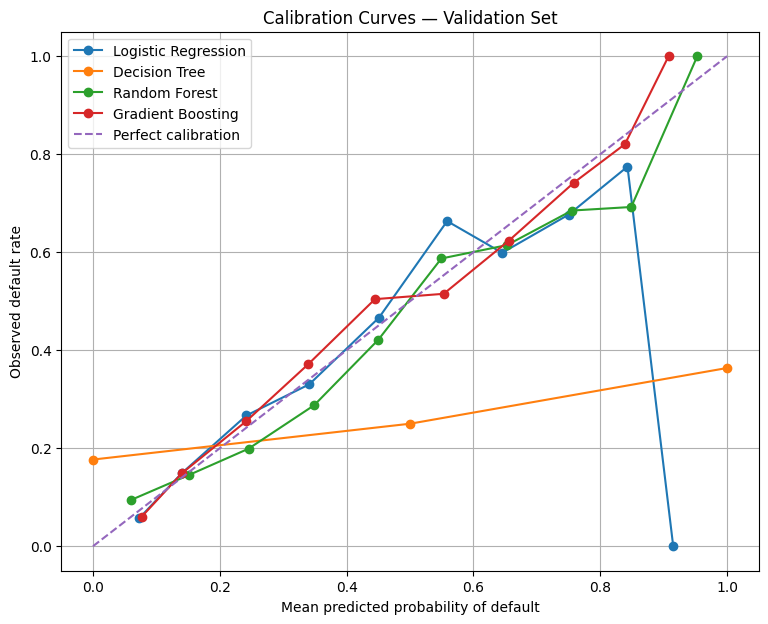

In [33]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

models_and_probabilities = {
    "Logistic Regression": y_val_logistic_prob,
    "Decision Tree": y_val_tree_prob,
    "Random Forest": y_val_rf_prob,
    "Gradient Boosting": y_val_gb_prob
}

plt.figure(figsize=(9, 7))

for model_name, probabilities in models_and_probabilities.items():
    observed_rate, mean_predicted_probability = calibration_curve(
        y_val,
        probabilities,
        n_bins=10,
        strategy="uniform"
    )

    plt.plot(
        mean_predicted_probability,
        observed_rate,
        marker="o",
        label=model_name
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")

plt.xlabel("Mean predicted probability of default")
plt.ylabel("Observed default rate")
plt.title("Calibration Curves — Validation Set")
plt.legend()
plt.grid(True)
plt.show()

# 5. Group-Level Error Analysis

This section examines whether the models produce different error rates across demographic groups. The analysis focuses on false positive rates, false negative rates and recall.

## 5.1 Gender-Based Error Analysis

The validation dataset is grouped by gender using the dataset's gender codes. For each model, a confusion matrix is calculated within each group to determine the false positive rate, false negative rate and recall.

This analysis helps identify differences in prediction errors across groups. Such differences may be relevant when evaluating models intended for high-stakes financial decisions.


In [34]:
import pandas as pd
from sklearn.metrics import confusion_matrix

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model
}

group_results = []

# Use the validation set for this analysis
for model_name, model in models.items():
    predictions = model.predict(X_val)

    # Match predictions to the original validation features
    results = pd.DataFrame({
        "Gender": X_val["X2"].to_numpy(),
        "Actual": y_val.to_numpy(),
        "Predicted": predictions
    })

    for gender, group in results.groupby("Gender"):
        tn, fp, fn, tp = confusion_matrix(
            group["Actual"],
            group["Predicted"],
            labels=[0, 1]
        ).ravel()

        group_results.append({
            "Model": model_name,
            "Gender code": gender,
            "Customers": len(group),
            "False positive rate": fp / (fp + tn) if (fp + tn) else 0,
            "False negative rate": fn / (fn + tp) if (fn + tp) else 0,
            "Recall": tp / (tp + fn) if (tp + fn) else 0
        })

gender_results = pd.DataFrame(group_results)

print(gender_results.round(4).to_string(index=False))

              Model  Gender code  Customers  False positive rate  False negative rate  Recall
Logistic Regression            1       1797               0.0538               0.6368  0.3632
Logistic Regression            2       2703               0.0445               0.6577  0.3423
      Decision Tree            1       1797               0.1921               0.6070  0.3930
      Decision Tree            2       2703               0.1938               0.6138  0.3862
      Random Forest            1       1797               0.0566               0.6194  0.3806
      Random Forest            2       2703               0.0573               0.6425  0.3575
  Gradient Boosting            1       1797               0.0538               0.6443  0.3557
  Gradient Boosting            2       2703               0.0493               0.6526  0.3474


## 5.2 Education-Based Error Analysis

This analysis examines model performance across the education categories recorded in the dataset.

For each model, customers are grouped by education code, and false positive rate, false negative rate and recall are calculated using the group's confusion matrix.

The number of customers in each group is also reported because group size affects how reliably error rates can be interpreted. Results for groups with very small sample sizes should be treated with caution.

In [35]:
education_results = []

for model_name, model in models.items():
    predictions = model.predict(X_val)

    results = pd.DataFrame({
        "Education code": X_val["X3"].to_numpy(),
        "Actual": y_val.to_numpy(),
        "Predicted": predictions
    })

    for education, group in results.groupby("Education code"):
        tn, fp, fn, tp = confusion_matrix(
            group["Actual"],
            group["Predicted"],
            labels=[0, 1]
        ).ravel()

        education_results.append({
            "Model": model_name,
            "Education code": education,
            "Customers": len(group),
            "False positive rate": fp / (fp + tn) if (fp + tn) else 0,
            "False negative rate": fn / (fn + tp) if (fn + tp) else 0,
            "Recall": tp / (tp + fn) if (tp + fn) else 0
        })

education_results = pd.DataFrame(education_results)

print(education_results.round(4).to_string(index=False))

              Model  Education code  Customers  False positive rate  False negative rate  Recall
Logistic Regression               0          2               0.0000               0.0000  0.0000
Logistic Regression               1       1626               0.0297               0.6953  0.3047
Logistic Regression               2       2111               0.0526               0.6266  0.3734
Logistic Regression               3        711               0.0843               0.6328  0.3672
Logistic Regression               4         15               0.0000               1.0000  0.0000
Logistic Regression               5         29               0.0000               1.0000  0.0000
Logistic Regression               6          6               0.2500               1.0000  0.0000
      Decision Tree               0          2               0.5000               0.0000  0.0000
      Decision Tree               1       1626               0.1693               0.6452  0.3548
      Decision Tree           

## 5.3 Overall Model Performance Comparison

This section brings together the validation-set results for all four models to provide a consolidated comparison.

The evaluation includes accuracy, precision, recall, F1-score and ROC-AUC, alongside the Brier score. These metrics provide different perspectives on predictive performance and probability quality.

The comparison helps identify trade-offs between the models rather than relying on a single performance metric.

In [36]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss
)

models_and_probabilities = {
    "Logistic Regression": (logistic_model, y_val_logistic_prob),
    "Decision Tree": (decision_tree_model, y_val_tree_prob),
    "Random Forest": (random_forest_model, y_val_rf_prob),
    "Gradient Boosting": (gradient_boosting_model, y_val_gb_prob)
}

comparison = []

for name, (model, probabilities) in models_and_probabilities.items():
    predictions = model.predict(X_val)

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "Brier score": brier_score_loss(y_val, probabilities)
    })

comparison_df = pd.DataFrame(comparison)

print(comparison_df.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall  F1-score  ROC-AUC  Brier score
Logistic Regression    0.8189     0.6737  0.3508    0.4613   0.7655       0.1384
      Decision Tree    0.7144     0.3637  0.3889    0.3759   0.5980       0.2856
      Random Forest    0.8156     0.6460  0.3668    0.4679   0.7521       0.1404
  Gradient Boosting    0.8167     0.6610  0.3508    0.4583   0.7795       0.1356


## 5.4 Validation Baseline Comparison

The majority-class baseline is evaluated on the validation set to provide a reference point for comparing the four trained models.

The baseline predicts the most frequent class for every customer. Its accuracy, precision, recall, F1-score, ROC-AUC and Brier score are calculated using the same evaluation metrics applied to the other models.

Comparing these results with the trained models helps determine whether the models provide predictive value beyond a simple majority-class prediction.

In [37]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss
)

baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(X_train, y_train)

baseline_val_pred = baseline_model.predict(X_val)
baseline_val_prob = baseline_model.predict_proba(X_val)[:, 1]

print("Baseline — Validation Results")
print("-----------------------------")
print("Accuracy:", round(accuracy_score(y_val, baseline_val_pred), 4))
print("Precision:", round(precision_score(
    y_val, baseline_val_pred, zero_division=0
), 4))
print("Recall:", round(recall_score(
    y_val, baseline_val_pred, zero_division=0
), 4))
print("F1-score:", round(f1_score(
    y_val, baseline_val_pred, zero_division=0
), 4))
print("ROC-AUC:", round(roc_auc_score(
    y_val, baseline_val_prob
), 4))
print("Brier score:", round(brier_score_loss(
    y_val, baseline_val_prob
), 4))

Baseline — Validation Results
-----------------------------
Accuracy: 0.7789
Precision: 0.0
Recall: 0.0
F1-score: 0.0
ROC-AUC: 0.5
Brier score: 0.2211


## 5.5 Classification Threshold Analysis

A classification threshold determines the probability at which a customer is classified as likely to default.

This analysis evaluates the Gradient Boosting model at thresholds of 0.3, 0.4 and 0.5 using the validation set.

For each threshold, precision, recall, F1-score, false positive rate and false negative rate are calculated. The purpose is to examine how changing the threshold affects the balance between identifying actual defaults and incorrectly classifying customers.

This is particularly relevant in credit-risk prediction, where false positives and false negatives can have different consequences.

In [38]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

threshold_results = []

for threshold in [0.3, 0.4, 0.5]:
    predictions = (y_val_gb_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "False positive rate": fp / (fp + tn),
        "False negative rate": fn / (fn + tp)
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(4).to_string(index=False))

 Threshold  Precision  Recall  F1-score  False positive rate  False negative rate
       0.3     0.5581  0.5065    0.5311               0.1138               0.4935
       0.4     0.6321  0.4111    0.4982               0.0679               0.5889
       0.5     0.6610  0.3508    0.4583               0.0511               0.6492


## 5.6 Threshold Comparison Across All Models

This analysis compares the effect of different classification thresholds across all four machine-learning models.

Each model is evaluated at thresholds of 0.3, 0.4 and 0.5 using the validation set. Precision, recall, F1-score, false positive rate and false negative rate are calculated for each combination.

The comparison highlights how threshold adjustments affect the models differently and helps illustrate the trade-offs involved in selecting a classification threshold for credit-risk prediction.

In [39]:
threshold_comparison = []

probabilities_by_model = {
    "Logistic Regression": y_val_logistic_prob,
    "Decision Tree": y_val_tree_prob,
    "Random Forest": y_val_rf_prob,
    "Gradient Boosting": y_val_gb_prob
}

for model_name, probabilities in probabilities_by_model.items():
    for threshold in [0.3, 0.4, 0.5]:
        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val, predictions, labels=[0, 1]
        ).ravel()

        threshold_comparison.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "F1-score": f1_score(
                y_val, predictions, zero_division=0
            ),
            "False positive rate": fp / (fp + tn),
            "False negative rate": fn / (fn + tp)
        })

threshold_comparison_df = pd.DataFrame(threshold_comparison)

print(threshold_comparison_df.round(4).to_string(index=False))

              Model  Threshold  Precision  Recall  F1-score  False positive rate  False negative rate
Logistic Regression        0.3     0.5565  0.4704    0.5098               0.1064               0.5296
Logistic Regression        0.4     0.6431  0.3930    0.4878               0.0619               0.6070
Logistic Regression        0.5     0.6737  0.3508    0.4613               0.0482               0.6492
      Decision Tree        0.3     0.3633  0.3899    0.3762               0.1940               0.6101
      Decision Tree        0.4     0.3633  0.3899    0.3762               0.1940               0.6101
      Decision Tree        0.5     0.3633  0.3899    0.3762               0.1940               0.6101
      Random Forest        0.3     0.4950  0.5437    0.5182               0.1575               0.4563
      Random Forest        0.4     0.5754  0.4603    0.5114               0.0964               0.5397
      Random Forest        0.5     0.6432  0.3769    0.4753               0.0593  

# 6. Final Model Evaluation on the Test Set

After the validation-stage comparisons, the four trained models are evaluated on the test set.

The evaluation uses accuracy, precision, recall, F1-score, ROC-AUC and Brier score to assess predictive performance and probability quality.

These results provide a final comparison of the models on the test split. They are considered alongside the validation findings when discussing the strengths, limitations and trade-offs of each model.

In [40]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss
)
import pandas as pd

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model
}

test_results = []

for model_name, model in models.items():
    # Generate predictions on the test set
    y_test_pred = model.predict(X_test)
    y_test_prob = model.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    test_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_test_pred),
        "Precision": precision_score(
            y_test, y_test_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_test_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_test_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_test_prob),
        "Brier score": brier_score_loss(y_test, y_test_prob)
    })

test_results_df = pd.DataFrame(test_results)

print(test_results_df.round(4).to_string(index=False))


              Model  Accuracy  Precision  Recall  F1-score  ROC-AUC  Brier score
Logistic Regression    0.8162     0.6634  0.3444    0.4534   0.7602       0.1381
      Decision Tree    0.7278     0.3921  0.4177    0.4045   0.6174       0.2721
      Random Forest    0.8151     0.6424  0.3715    0.4707   0.7602       0.1397
  Gradient Boosting    0.8144     0.6516  0.3474    0.4532   0.7820       0.1351


## 6.1 Test-Set Probability Calibration

This section examines how closely the predicted probabilities from each model correspond to the observed default rates on the test set.

The calibration curves compare each model against a diagonal reference line representing perfect calibration. Curves closer to this line indicate better agreement between predicted probabilities and observed outcomes.

Comparing these curves with the validation-set calibration results provides an additional perspective on how the models' probability estimates perform on the test split.

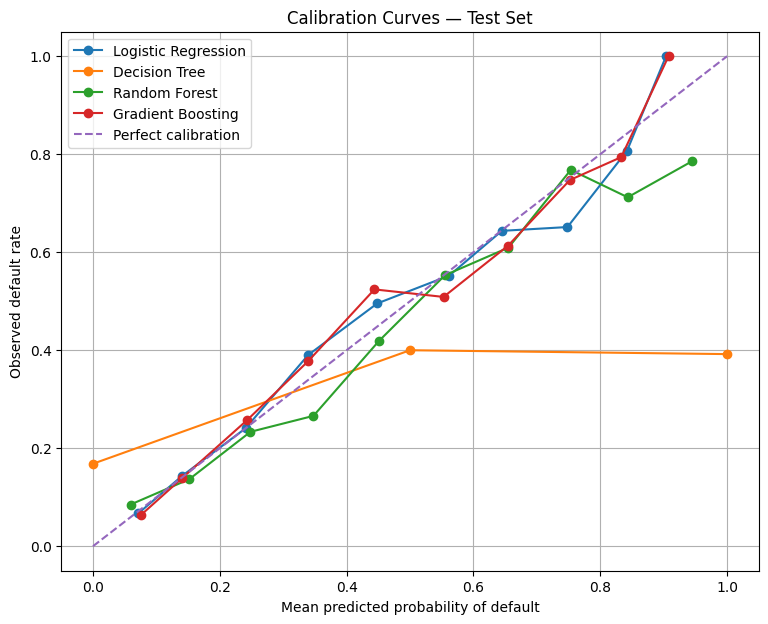

Number of test observations in each calibration bin:


,Model,Probability Bin,Observations
0,Logistic Regression,0.0–0.1,807
1,Logistic Regression,0.1–0.2,2361
2,Logistic Regression,0.2–0.3,465
3,Logistic Regression,0.3–0.4,241
4,Logistic Regression,0.4–0.5,109
5,Logistic Regression,0.5–0.6,105
6,Logistic Regression,0.6–0.7,188
7,Logistic Regression,0.7–0.8,109
8,Logistic Regression,0.8–0.9,114
9,Logistic Regression,0.9–1.0,1


In [41]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve

models_and_test_probabilities = {
    "Logistic Regression": logistic_model.predict_proba(X_test)[:, 1],
    "Decision Tree": decision_tree_model.predict_proba(X_test)[:, 1],
    "Random Forest": random_forest_model.predict_proba(X_test)[:, 1],
    "Gradient Boosting": gradient_boosting_model.predict_proba(X_test)[:, 1]
}

plt.figure(figsize=(9, 7))

bin_edges = np.linspace(0, 1, 11)
all_bin_counts = []

for model_name, probabilities in models_and_test_probabilities.items():

    observed_rate, mean_predicted_probability = calibration_curve(
        y_test,
        probabilities,
        n_bins=10,
        strategy="uniform"
    )

    plt.plot(
        mean_predicted_probability,
        observed_rate,
        marker="o",
        label=model_name
    )

    bin_indices = np.searchsorted(
        bin_edges[1:-1],
        probabilities
    )

    bin_counts = np.bincount(
        bin_indices,
        minlength=10
    )

    for i, count in enumerate(bin_counts):
        if count > 0:
            all_bin_counts.append({
                "Model": model_name,
                "Probability Bin": f"{bin_edges[i]:.1f}–{bin_edges[i+1]:.1f}",
                "Observations": count
            })

plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
plt.xlabel("Mean predicted probability of default")
plt.ylabel("Observed default rate")
plt.title("Calibration Curves — Test Set")
plt.legend()
plt.grid(True)
plt.show()

bin_counts_df = pd.DataFrame(all_bin_counts)

print("Number of test observations in each calibration bin:")
display(bin_counts_df)

## 6.2 Test-Set Gender-Based Error Analysis

This analysis examines whether the models produce different prediction errors across gender groups on the test set.

Customers are grouped using the gender codes recorded in the dataset. For each model and group, the false positive rate (FPR), false negative rate (FNR) and recall are calculated.

The results are compared with the validation-stage gender analysis to examine whether the observed differences in error rates persist across the two data splits.

These findings should be interpreted carefully. Differences in group-level error rates do not, by themselves, establish discrimination or explain the causes of those differences.

In [42]:

from sklearn.metrics import confusion_matrix
import pandas as pd

group_results = []

for model_name, model in models.items():
    y_pred = model.predict(X_test)

    for group in sorted(X_test["X2"].unique()):
        mask = X_test["X2"] == group

        tn, fp, fn, tp = confusion_matrix(
            y_test[mask],
            y_pred[mask],
            labels=[0, 1]
        ).ravel()

        group_results.append({
            "Model": model_name,
            "Gender code": group,
            "Customers": int(mask.sum()),
            "FPR": fp / (fp + tn) if (fp + tn) else 0,
            "FNR": fn / (fn + tp) if (fn + tp) else 0,
            "Recall": tp / (tp + fn) if (tp + fn) else 0
        })

gender_test_results = pd.DataFrame(group_results)

print(gender_test_results.round(4).to_string(index=False))


              Model  Gender code  Customers    FPR    FNR  Recall
Logistic Regression            1       1766 0.0524 0.6853  0.3147
Logistic Regression            2       2734 0.0480 0.6314  0.3686
      Decision Tree            1       1766 0.2018 0.5826  0.4174
      Decision Tree            2       2734 0.1734 0.5821  0.4179
      Random Forest            1       1766 0.0645 0.6607  0.3393
      Random Forest            2       2734 0.0554 0.6022  0.3978
  Gradient Boosting            1       1766 0.0539 0.6964  0.3036
  Gradient Boosting            2       2734 0.0522 0.6168  0.3832


## 6.3 Test-Set Education-Based Error Analysis

This analysis examines model prediction errors across the education categories represented in the test dataset.

For each model and education group, the false positive rate (FPR), false negative rate (FNR) and recall are calculated. The number of customers in each group is also reported to provide context when interpreting the results.

The findings are compared with the validation-stage education analysis to examine whether differences in error rates persist across the two data splits.

Results from groups with very small sample sizes should be interpreted cautiously because their error rates may be unstable.

In [43]:

education_results = []

for model_name, model in models.items():
    y_pred = model.predict(X_test)

    for group in sorted(X_test["X3"].unique()):
        mask = X_test["X3"] == group

        tn, fp, fn, tp = confusion_matrix(
            y_test[mask],
            y_pred[mask],
            labels=[0, 1]
        ).ravel()

        education_results.append({
            "Model": model_name,
            "Education code": group,
            "Customers": int(mask.sum()),
            "FPR": fp / (fp + tn) if (fp + tn) else 0,
            "FNR": fn / (fn + tp) if (fn + tp) else 0,
            "Recall": tp / (tp + fn) if (tp + fn) else 0
        })

education_test_results = pd.DataFrame(education_results)

print(education_test_results.round(4).to_string(index=False))


              Model  Education code  Customers    FPR    FNR  Recall
Logistic Regression               1       1580 0.0286 0.7250  0.2750
Logistic Regression               2       2086 0.0628 0.6101  0.3899
Logistic Regression               3        766 0.0650 0.6497  0.3503
Logistic Regression               4         20 0.0000 1.0000  0.0000
Logistic Regression               5         40 0.0000 1.0000  0.0000
Logistic Regression               6          8 0.0000 0.0000  0.0000
      Decision Tree               1       1580 0.1635 0.5875  0.4125
      Decision Tree               2       2086 0.1827 0.5681  0.4319
      Decision Tree               3        766 0.2302 0.6091  0.3909
      Decision Tree               4         20 0.1053 0.0000  1.0000
      Decision Tree               5         40 0.2051 1.0000  0.0000
      Decision Tree               6          8 0.5000 0.0000  0.0000
      Random Forest               1       1580 0.0452 0.6562  0.3438
      Random Forest               

## 6.4 Validation and Test Performance Comparison

This section presents the validation and test performance metrics side by side for all four models.

The comparison includes accuracy, precision, recall, F1-score, ROC-AUC and Brier score. It provides an overview of how model performance changes between the validation and test splits.

The results help assess the consistency of each model's predictive performance and probability estimates across the two data splits.

This table presents a consolidated comparison of all four models on the validation and test sets. The same classification threshold of 0.5 is applied across the models to ensure consistency. The results allow us to examine how well each model performs on both datasets using accuracy, precision, recall, F1-score, ROC-AUC and Brier score.

In [44]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, brier_score_loss
)
import pandas as pd

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model
}

rows = []

for model_name, model in models.items():
    for split_name, X_split, y_split in [
        ("Validation", X_val, y_val),
        ("Test", X_test, y_test)
    ]:
        probabilities = model.predict_proba(X_split)[:, 1]
        predictions = (probabilities >= 0.5).astype(int)

        rows.append({
            "Model": model_name,
            "Dataset": split_name,
            "Accuracy": accuracy_score(y_split, predictions),
            "Precision": precision_score(
                y_split, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_split, predictions, zero_division=0
            ),
            "F1-score": f1_score(
                y_split, predictions, zero_division=0
            ),
            "ROC-AUC": roc_auc_score(y_split, probabilities),
            "Brier score": brier_score_loss(y_split, probabilities)
        })

final_comparison = pd.DataFrame(rows)

display(
    final_comparison
    .sort_values(["Model", "Dataset"])
    .round(4)
)


,Model,Dataset,Accuracy,Precision,Recall,F1-score,ROC-AUC,Brier score
3,Decision Tree,Test,0.7276,0.3921,0.4197,0.4054,0.6174,0.2721
2,Decision Tree,Validation,0.7140,0.3633,0.3899,0.3762,0.5980,0.2856
7,Gradient Boosting,Test,0.8144,0.6516,0.3474,0.4532,0.7820,0.1351
6,Gradient Boosting,Validation,0.8167,0.6610,0.3508,0.4583,0.7795,0.1356
1,Logistic Regression,Test,0.8162,0.6634,0.3444,0.4534,0.7602,0.1381
0,Logistic Regression,Validation,0.8189,0.6737,0.3508,0.4613,0.7655,0.1384
5,Random Forest,Test,0.8131,0.6311,0.3745,0.4701,0.7602,0.1397
4,Random Forest,Validation,0.8160,0.6432,0.3769,0.4753,0.7521,0.1404


# 7. Results and Discussion

This section interprets the results obtained from the four machine-learning models, focusing on predictive performance, probability quality and the trade-offs between different evaluation metrics.

## 7.1 Predictive Performance

The test results show that the four models performed differently across the evaluation metrics.

Random Forest achieved the highest F1-score (0.4701), indicating the strongest balance between precision and recall among the four models. Logistic Regression recorded the highest accuracy (0.8162) and precision (0.6634), while Gradient Boosting achieved the highest ROC-AUC (0.7820), suggesting the strongest ability to distinguish between clients who defaulted and those who did not.

Decision Tree achieved the highest recall (0.4197), identifying a larger proportion of actual defaulters. However, it also had substantially lower accuracy (0.7276) and ROC-AUC (0.6174).

Overall, no single model performed best across every metric. The results illustrate why model selection should depend on the intended use of the predictions rather than accuracy alone.

## 7.2 Probability Quality and Calibration

Gradient Boosting achieved the lowest Brier score on the test set (0.1351), followed by Logistic Regression (0.1381) and Random Forest (0.1397). Decision Tree recorded a considerably higher Brier score (0.2721).

The calibration curves provide further insight into the probability estimates produced by the models. Logistic Regression and Gradient Boosting generally followed the perfect-calibration reference line more closely across much of the probability range, although both showed deviations in certain intervals.

Random Forest displayed noticeable deviations at higher predicted probabilities. Decision Tree showed the largest visible departure from the reference line, particularly in the highest probability bin, where the mean predicted probability was approximately 1.0 but the observed default rate was approximately 0.39.

These observations suggest that the models differ in how reliably their predicted probabilities correspond to observed default frequencies. The Brier score and calibration curves provide complementary information, but neither alone establishes that a model is suitable for deployment.

This distinction is important in high-stakes financial applications, where decision-makers may rely on predicted probabilities rather than only on the final predicted class.

The bin-count analysis provides additional context for interpreting the calibration curves. In the highest probability bin (0.9–1.0), Decision Tree had 1,061 test observations, compared with only 1 for Logistic Regression, 14 for Random Forest and 3 for Gradient Boosting. Despite its large sample in this bin, Decision Tree recorded an observed default rate of approximately 0.39, indicating substantial overestimation of default probabilities. The very small sample sizes in the corresponding bins for the other models mean that their calibration estimates at the highest probability range should be interpreted cautiously.

## 7.3 Gender-Based Error Analysis

The gender-based evaluation revealed differences in false negative rates (FNR) across the models.

For Logistic Regression, the false negative rate was 0.6853 for clients coded as gender 1 and 0.6314 for clients coded as gender 2. Random Forest recorded corresponding rates of 0.6607 and 0.6022, while Gradient Boosting recorded 0.6964 and 0.6168.

Decision Tree showed almost identical false negative rates across the two groups, at 0.5826 and 0.5821.

These results indicate that the models did not produce identical error patterns across the gender groups. In particular, Gradient Boosting showed the largest observed false negative rate difference, approximately 7.96 percentage points.

However, differences in group-level error rates alone do not establish that a model is discriminatory. They should be interpreted alongside group sizes, data quality, other relevant variables and the limitations of the dataset.

## 7.4 Education-Based Error Analysis

The education-based analysis examined whether false positive and false negative rates varied across the education categories in the dataset.

The results should be interpreted cautiously because the education groups were not equally represented. In particular, categories 4, 5 and 6 contained very small numbers of observations (20, 40 and 8 respectively in the test set). Error rates calculated from such small groups can be unstable and may not provide reliable evidence of differences in model behaviour.

This analysis highlights the importance of considering group sizes when evaluating fairness. A difference in error rates should not automatically be interpreted as evidence of discrimination, especially when the affected group has very few observations.

## 7.5 Classification Threshold and Error Trade-offs

The threshold analysis on the validation set showed that changing the classification threshold affects the balance between identifying actual defaulters and incorrectly classifying non-defaulters.

For Logistic Regression, reducing the threshold from 0.5 to 0.3 increased recall from 0.3508 to 0.4704, while the false positive rate increased from 0.0482 to 0.1064.

Random Forest showed a similar pattern: recall increased from 0.3769 at a threshold of 0.5 to 0.5437 at 0.3, while the false positive rate increased from 0.0593 to 0.1575.

Gradient Boosting also achieved higher recall at the lower threshold, increasing from 0.3508 to 0.5065, alongside an increase in its false positive rate from 0.0511 to 0.1138.

Decision Tree produced the same results at the three tested thresholds, illustrating that its predicted probabilities did not change enough within this threshold range to alter its classifications.

These findings demonstrate a trade-off: lowering the threshold can help identify more potential defaulters, but it can also increase false alarms. The appropriate threshold therefore depends on the costs of missed defaults and incorrect default predictions.

The threshold comparisons were conducted using the validation set; the final test-set evaluation retained a threshold of 0.5.

# 8. Limitations and Responsible AI Considerations

Despite the comparative analysis, several limitations should be considered when interpreting the findings.

## 8.1 Dataset Limitations

The study uses the UCI Default of Credit Card Clients dataset, which contains information on credit-card clients in Taiwan. Its findings may not generalise directly to other populations, financial institutions or countries, including Nigeria.

The dataset also contains duplicate feature records and groups with conflicting target labels. These data-quality issues may affect the reliability of the patterns learned by the models.

## 8.2 Model and Evaluation Limitations

The study compares four machine-learning models using their default configurations rather than conducting an extensive hyperparameter optimisation process. Different configurations may produce different results.

The classification threshold of 0.5 was used for the final test-set comparison. Although alternative thresholds were explored on the validation set, the study does not establish an optimal threshold for a real financial institution.

The Brier score and calibration curves provide useful information about probability quality, but they do not independently establish that a model is suitable for deployment.

## 8.3 Fairness and Responsible AI

The group-level analysis focused on gender and education categories available in the dataset. These comparisons provide an initial assessment of differences in model errors, but they do not constitute a complete fairness evaluation.

Some education categories had very small sample sizes, making their error rates unstable. Furthermore, differences in false positive or false negative rates do not, on their own, prove discriminatory behaviour.

In a real financial application, model predictions should be evaluated alongside data quality, transparency, privacy, regulatory requirements and the potential consequences of incorrect decisions. Human oversight would also be important before using predictions to influence credit-related decisions.

# 9. Conclusion

This study compared Logistic Regression, Decision Tree, Random Forest and Gradient Boosting for predicting credit-card payment default using the UCI Default of Credit Card Clients dataset.

The results showed that no single model performed best across all evaluation metrics. Random Forest achieved the highest test F1-score, Gradient Boosting recorded the highest ROC-AUC and lowest Brier score, while Decision Tree achieved the highest recall. These differences demonstrate the trade-offs involved in selecting a model for a financial prediction task.

The calibration and group-level analyses further showed why predictive performance alone is insufficient when evaluating models for high-stakes applications. Probability quality, differences in error rates, data quality and the consequences of incorrect predictions must also be considered.

Overall, the findings highlight the importance of evaluating machine-learning models from multiple perspectives before considering their use in financial decision-making. Further work could explore hyperparameter optimisation, additional fairness metrics, alternative classification thresholds and model explainability.

# 10. References

1. Yeh, I-C., & Lien, C-H. (2009). The comparisons of data mining techniques for the predictive accuracy of probability of default of credit card clients. *Expert Systems with Applications, 36*(2), 2473–2480. https://doi.org/10.1016/j.eswa.2007.12.020

2. Yeh, I. (2009). *Default of Credit Card Clients* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C55S3H

3. Scikit-learn developers. *Scikit-learn: Machine Learning in Python*. https://scikit-learn.org/stable/
